# Problem 2 Transformer

BITS ID: **2026aj05054**

Chosen values: recurrent hidden size 48, Transformer width 96, seeds 7, 21 and 42. The language model uses four layers, four heads and context 128.


In [1]:
from pathlib import Path
from types import SimpleNamespace
import os, random, json, math, time, csv, tempfile, copy, zipfile, urllib.request
import gc, resource, sys, subprocess, importlib.util, io

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Colab provides current packages; keep its working runtime instead of installing
# Python-3.10-only pins. Local installation uses requirements.txt before Run All.
if IN_COLAB:
    packages = {'torch':'torch>=2.5,<3', 'numpy':'numpy>=1.26',
                'pandas':'pandas>=2', 'matplotlib':'matplotlib>=3.9',
                'IPython':'ipython'}
    missing = [package for module,package in packages.items()
               if importlib.util.find_spec(module) is None]
    if missing:
        subprocess.check_call([sys.executable,'-m','pip','install',*missing])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display, Image, FileLink

ASSIGNMENT_NAME = '2026aj05054_DNN_Assignment'
CURRENT_PROBLEM = 'problem2'

def find_assignment_root(start):
    start = Path(start).resolve()
    for parent in (start, *start.parents):
        for candidate in (parent, parent/ASSIGNMENT_NAME):
            required = ['requirements.txt', 'problem1/problem1.ipynb',
                        'problem2/problem2.ipynb']
            if all((candidate/name).is_file() for name in required):
                return candidate
    return None

def unpack_assignment_zip(archive):
    destination = Path(tempfile.mkdtemp(prefix='dnn-assignment-')).resolve()
    with zipfile.ZipFile(archive) as bundle:
        for member in bundle.infolist():
            target = (destination/member.filename).resolve()
            is_link = (member.external_attr >> 16) & 0o170000 == 0o120000
            if not target.is_relative_to(destination) or is_link or '\\' in member.filename:
                raise ValueError('ZIP contains a path outside its destination.')
        bundle.extractall(destination)
    candidates = {find_assignment_root(p.parent) for p in destination.rglob('problem1.ipynb')}
    candidates.discard(None)
    candidates = {root for root in candidates if root.is_relative_to(destination)}
    if len(candidates) != 1:
        raise ValueError('Upload the full assignment ZIP with both problem folders.')
    return candidates.pop()

ROOT = find_assignment_root(Path.cwd())
if ROOT is None and IN_COLAB:
    if '--context-worker' in sys.argv:
        raise FileNotFoundError('Profiling worker must start in the assignment folder.')
    archives = sorted(Path.cwd().glob(ASSIGNMENT_NAME+'*.zip'))
    if archives:
        ROOT = unpack_assignment_zip(archives[-1])
    else:
        print('Upload the complete assignment ZIP (not just this notebook).')
        uploaded = colab_files.upload()
        zipped = [data for name,data in uploaded.items() if name.lower().endswith('.zip')]
        if len(zipped) != 1:
            raise ValueError('Select exactly one complete assignment ZIP.')
        ROOT = unpack_assignment_zip(io.BytesIO(zipped[0]))
if ROOT is None:
    raise FileNotFoundError('Open the extracted assignment folder in VS Code, then Run All.')
os.chdir(ROOT)

DATA_DIR = ROOT.parent/'.dnn_data'
if (ROOT.parent/'.qa/data').is_dir():
    DATA_DIR = ROOT.parent/'.qa/data'
CACHE_DIR = ROOT.parent/'.dnn_model_cache'
if (ROOT.parent/'.qa/student_cache').is_dir():
    CACHE_DIR = ROOT.parent/'.qa/student_cache'
CACHE_DIR.mkdir(parents=True, exist_ok=True)
REUSE_COMPLETED_RUNS = not IN_COLAB  # Colab trains afresh; local runs resume by default.

if torch.cuda.is_available():
    accelerator = torch.device('cuda')
elif torch.backends.mps.is_available():
    accelerator = torch.device('mps')
else:
    accelerator = torch.device('cpu')

# A local benchmark found CPU faster for the RNN/GRU loops on this Mac.
# All HAR models use the same device so their epoch times are comparable.
USE_ACCELERATOR_FOR_RECURRENT = False
har_device = accelerator if USE_ACCELERATOR_FOR_RECURRENT else torch.device('cpu')
config = SimpleNamespace(
    ROOT=ROOT, DATA_DIR=DATA_DIR, CACHE_DIR=CACHE_DIR,
    RESULTS_PATH=ROOT/'results.csv', STUDENT_ID='2026aj05054',
    STUDENT_NAME='Ganga Maheshwar Reddy Yeddula',
    SEEDS=(7,21,42), HIDDEN_SIZE=48, MODEL_DIM=96, HEADS=4, LAYERS=4,
    CONTEXT=128, BATCH_SIZE=128, LM_BATCH_SIZE=32, HAR_EPOCHS=8,
    ADDING_EPOCHS=12, LM_STEPS=600, LR=0.001, DROPOUT=0.1, THREADS=2,
    ACCELERATOR=accelerator, HAR_DEVICE=har_device, LM_DEVICE=accelerator,
    DEVICE=har_device, REUSE_COMPLETED_RUNS=REUSE_COMPLETED_RUNS)
cfg = config
torch.set_num_threads(config.THREADS)
print('PyTorch:', torch.__version__)
print('Available accelerator:', accelerator)
print('HAR/recurrent device:', config.HAR_DEVICE)
print('Transformer language-model device:', config.LM_DEVICE)
print('Environment:', 'Colab' if IN_COLAB else 'VS Code / local Python')
print('Reuse completed runs:', config.REUSE_COMPLETED_RUNS)
NOTEBOOK_STARTED = time.perf_counter()


PyTorch: 2.5.1
Available accelerator: mps
HAR/recurrent device: cpu
Transformer language-model device: mps
Environment: VS Code / local Python
Reuse completed runs: True


## Seeds metrics and result recording

The classification metrics use NumPy so they do not import SciPy. Results are written after each completed run.


In [2]:
COLUMNS = ["problem", "model", "seed", "seq_len", "test_acc", "macro_f1",
           "test_mse", "params", "sec_per_epoch", "val_loss_nats",
           "bits_per_char", "notes"]

def _classification_targets(y_true, y_pred):
    """Validate the one-dimensional, nonempty label vectors used by this task."""
    true, predicted = np.asarray(y_true), np.asarray(y_pred)
    if true.ndim != 1 or predicted.ndim != 1 or true.shape != predicted.shape:
        raise ValueError('Expected matching one-dimensional classification targets.')
    if true.size == 0:
        raise ValueError('Classification metrics require at least one example.')
    return true, predicted


def accuracy_score(y_true, y_pred):
    """Fraction of correctly classified examples, without a SciPy dependency."""
    true, predicted = _classification_targets(y_true, y_pred)
    return float(np.mean(true == predicted))


def confusion_matrix(y_true, y_pred, labels=None):
    """Integer count matrix, with true classes on rows and predictions on columns."""
    true, predicted = _classification_targets(y_true, y_pred)
    selected = (np.unique(np.concatenate([true, predicted]))
                if labels is None else np.asarray(labels))
    if selected.ndim != 1 or selected.size == 0 or len(set(selected.tolist())) != len(selected):
        raise ValueError('labels must be a nonempty sequence of distinct classes.')
    positions = {label: index for index, label in enumerate(selected.tolist())}
    matrix = np.zeros((len(selected), len(selected)), dtype=np.int64)
    for actual, prediction in zip(true.tolist(), predicted.tolist()):
        if actual in positions and prediction in positions:
            matrix[positions[actual], positions[prediction]] += 1
    return matrix


def f1_score(y_true, y_pred, *, labels=None, average='macro', zero_division=0):
    """Macro F1 for the assignment; absent classes follow zero_division=0 or 1.

    Count each class against the full target vectors. This preserves false
    positives/negatives when an explicit label list selects only some classes.
    """
    if average != 'macro' or zero_division not in (0, 1):
        raise ValueError('This helper supports macro F1 and zero_division 0 or 1.')
    true, predicted = _classification_targets(y_true, y_pred)
    selected = (np.unique(np.concatenate([true, predicted]))
                if labels is None else np.asarray(labels))
    if selected.ndim != 1 or selected.size == 0 or len(set(selected.tolist())) != len(selected):
        raise ValueError('labels must be a nonempty sequence of distinct classes.')
    scores = []
    for label in selected:
        actual_positive, predicted_positive = true == label, predicted == label
        true_positives = int(np.count_nonzero(actual_positive & predicted_positive))
        denominator = int(np.count_nonzero(actual_positive) + np.count_nonzero(predicted_positive))
        scores.append(2.0 * true_positives / denominator if denominator else float(zero_division))
    return float(np.mean(scores))


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def append_result(**kwargs):
    """Save after each run. Sequential writers only; reruns replace an identity."""
    unknown = set(kwargs) - set(COLUMNS)
    if unknown:
        raise ValueError(f"Unexpected results columns: {sorted(unknown)}")
    row = {key: "" if kwargs.get(key) is None else str(kwargs.get(key, ""))
           for key in COLUMNS}
    for key in COLUMNS[4:11]:
        if row[key] and not math.isfinite(float(row[key])):
            raise ValueError(f"Non-finite {key}; record the failed run separately.")
    if row["val_loss_nats"] and row["bits_per_char"]:
        assert math.isclose(float(row["bits_per_char"]),
                            float(row["val_loss_nats"]) / math.log(2), rel_tol=1e-6)
    path = Path(config.RESULTS_PATH)
    path.parent.mkdir(parents=True, exist_ok=True)
    old = []
    if path.exists():
        with path.open(newline="", encoding="utf-8") as stream:
            reader = csv.DictReader(stream)
            if reader.fieldnames != COLUMNS:
                raise ValueError("Existing results.csv schema differs from assignment.")
            old = list(reader)
    keys = ("problem", "model", "seed", "seq_len", "notes")
    identity = tuple(row[key] for key in keys)
    old = [r for r in old if tuple(r[key] for key in keys) != identity]
    old.append(row)
    fd, temporary = tempfile.mkstemp(dir=path.parent, prefix=".results-", suffix=".csv")
    try:
        with os.fdopen(fd, "w", newline="", encoding="utf-8") as stream:
            writer = csv.DictWriter(stream, fieldnames=COLUMNS)
            writer.writeheader()
            writer.writerows(old)
            stream.flush()
            os.fsync(stream.fileno())
        os.replace(temporary, path)
    finally:
        if Path(temporary).exists():
            Path(temporary).unlink()


def begin_problem_run(problem):
    """Fresh training replaces this problem's rows, preserving the other problem."""
    if config.REUSE_COMPLETED_RUNS:
        return
    path = ROOT/'results.csv'
    if path.exists():
        with path.open(newline='',encoding='utf-8') as stream:
            reader = csv.DictReader(stream)
            if reader.fieldnames != COLUMNS:
                raise ValueError('Existing results.csv has a different schema.')
            kept = [row for row in reader if row['problem'] != 'P'+problem[-1]]
        with tempfile.NamedTemporaryFile('w',newline='',encoding='utf-8',
                                         dir=path.parent,delete=False) as stream:
            writer = csv.DictWriter(stream,fieldnames=COLUMNS)
            writer.writeheader(); writer.writerows(kept)
            temporary = stream.name
        os.replace(temporary,path)
    (ROOT/problem/'figures/notebook_runtime.json').unlink(missing_ok=True)

def finish_notebook_run():
    """Wall time from the end of setup through the final displayed results."""
    elapsed = time.perf_counter()-NOTEBOOK_STARTED
    record = {'problem':CURRENT_PROBLEM, 'elapsed_seconds':elapsed,
              'environment':'colab' if IN_COLAB else 'local',
              'reuse_completed_runs':config.REUSE_COMPLETED_RUNS,
              'python':sys.version.split()[0], 'torch':torch.__version__,
              'numpy':np.__version__, 'completed_at_unix':time.time(),
              'cuda_device_name':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
              'scope':'Setup excluded; includes definitions, tests, downloads, experiments, figures and samples. Cached replay is included when reuse is true.'}
    target = ROOT/CURRENT_PROBLEM/'figures/notebook_runtime.json'
    target.write_text(json.dumps(record,indent=2))
    print(f'Notebook elapsed: {elapsed/60:.2f} minutes. Runtime record: {target.relative_to(ROOT)}')
    if config.REUSE_COMPLETED_RUNS:
        print('This invocation allowed cached results; it is not a full-training benchmark.')

def export_run_files():
    """Save a portable ZIP; in Colab, first supply the executed UI notebook."""
    if IN_COLAB:
        print('First use File > Download > Download .ipynb. Then upload that executed notebook here.')
        uploaded = colab_files.upload()
        notebooks = [data for name,data in uploaded.items() if name.endswith('.ipynb')]
        if len(notebooks) != 1:
            raise ValueError('Upload exactly one executed notebook.')
        notebook = json.loads(notebooks[0])
        title = ''.join(notebook['cells'][0]['source'])
        if 'Problem '+CURRENT_PROBLEM[-1] not in title:
            raise ValueError('Upload the notebook for '+CURRENT_PROBLEM+'.')
        for cell in notebook['cells']:
            if cell['cell_type']=='code' and ''.join(cell['source']).strip():
                if cell.get('execution_count') is None or any(o.get('output_type')=='error' for o in cell.get('outputs',[])):
                    raise ValueError('Run all cells successfully and save outputs before exporting.')
        (ROOT/CURRENT_PROBLEM/(CURRENT_PROBLEM+'.ipynb')).write_bytes(notebooks[0])
    output = ROOT.parent/(ASSIGNMENT_NAME+'.zip')
    required = ['README.md','requirements.txt','report.pdf','results.csv',
                'problem1/problem1.ipynb','problem2/problem2.ipynb',
                'problem2/generated_samples.txt']
    with zipfile.ZipFile(output,'w',zipfile.ZIP_DEFLATED) as bundle:
        for relative in required:
            bundle.write(ROOT/relative,ASSIGNMENT_NAME+'/'+relative)
        for problem in ('problem1','problem2'):
            for path in sorted((ROOT/problem/'figures').rglob('*')):
                if path.is_file() and path.suffix in {'.png','.csv','.json','.txt'}:
                    if not any(part.startswith('.') for part in path.relative_to(ROOT).parts):
                        bundle.write(path,ASSIGNMENT_NAME+'/'+path.relative_to(ROOT).as_posix())
    if output.stat().st_size > 25_000_000:
        raise ValueError('Export exceeds the assignment 25 MB limit.')
    print('Saved',output.name,'- update report prose if rerun measurements changed.')
    if IN_COLAB:
        colab_files.download(str(output))
    else:
        display(FileLink(str(output)))
    return output


In [3]:
OUT = Path(cfg.ROOT) / 'problem2' / 'figures'

FIG = OUT

CACHE = Path(cfg.CACHE_DIR) / 'problem2'

for folder in (OUT, FIG, CACHE):
    folder.mkdir(parents=True, exist_ok=True)

cfg.RESULTS_PATH = ROOT/'results.csv'

VERSION = (f'manual_h{cfg.HIDDEN_SIZE}_d{cfg.MODEL_DIM}_l{cfg.LAYERS}'
           f'_ctx{cfg.CONTEXT}_har{cfg.HAR_EPOCHS}_b{cfg.BATCH_SIZE}'
           f'_lm{cfg.LM_STEPS}_b{cfg.LM_BATCH_SIZE}_lr{cfg.LR}_v2')


In [4]:
_HAR_RAW_CACHE=None
_HAR_SPLIT_CACHE={}
CHANNELS=('body_acc_x', 'body_acc_y', 'body_acc_z', 'body_gyro_x', 'body_gyro_y', 'body_gyro_z', 'total_acc_x', 'total_acc_y', 'total_acc_z')


In [5]:
def _extract_zip_safely(archive, destination):
    destination = Path(destination).resolve()
    with zipfile.ZipFile(archive) as zf:
        for member in zf.infolist():
            if not (destination / member.filename).resolve().is_relative_to(destination):
                raise ValueError("Archive contains a path outside the data directory")
        zf.extractall(destination)


def har_directory():
    """Download the official archive once, including its nested ZIP if present."""
    data = Path(config.DATA_DIR)
    data.mkdir(parents=True, exist_ok=True)
    candidates = list(data.rglob("UCI HAR Dataset/train/y_train.txt"))
    if not candidates:
        archive = data / "har.zip"
        if not archive.exists():
            urllib.request.urlretrieve(
                "https://archive.ics.uci.edu/static/public/240/"
                "human+activity+recognition+using+smartphones.zip", archive,
            )
        _extract_zip_safely(archive, data / "har")
        for nested in (data / "har").rglob("*.zip"):
            _extract_zip_safely(nested, nested.parent)
        candidates = list(data.rglob("UCI HAR Dataset/train/y_train.txt"))
    if len(candidates) != 1:
        raise RuntimeError(f"Expected one HAR directory, found {len(candidates)}")
    return candidates[0].parents[1]


def load_har(seed):
    """Subject-wise split and channel scaling fitted on the training part only."""
    global _HAR_RAW_CACHE
    if seed in _HAR_SPLIT_CACHE:
        return _HAR_SPLIT_CACHE[seed]
    if _HAR_RAW_CACHE is None:
        directory = har_directory()
        arrays = {}
        for split, count in (("train", 7352), ("test", 2947)):
            arrays[split] = np.stack([
                np.loadtxt(directory / split / "Inertial Signals" / f"{c}_{split}.txt",
                           dtype=np.float32) for c in CHANNELS
            ], axis=-1)
            assert arrays[split].shape == (count, 128, 9)
            arrays[f"y_{split}"] = np.loadtxt(
                directory / split / f"y_{split}.txt", dtype=np.int64,
            ) - 1
            arrays[f"s_{split}"] = np.loadtxt(
                directory / split / f"subject_{split}.txt", dtype=np.int64,
            )
        _HAR_RAW_CACHE = arrays
    arrays = _HAR_RAW_CACHE
    subjects = np.unique(arrays["s_train"])
    assert len(subjects) == 21 and len(np.unique(arrays["s_test"])) == 9
    assert not np.intersect1d(subjects, arrays["s_test"]).size
    val_subjects = np.random.default_rng(seed).choice(subjects, 4, replace=False)
    is_val = np.isin(arrays["s_train"], val_subjects)
    train_part = arrays["train"][~is_val]
    mean = train_part.mean(axis=(0, 1), dtype=np.float64).astype(np.float32)
    std = train_part.std(axis=(0, 1), dtype=np.float64).astype(np.float32)
    std = np.maximum(std, np.finfo(np.float32).eps)
    result = {
        "x_train": torch.from_numpy((train_part - mean) / std),
        "y_train": torch.from_numpy(arrays["y_train"][~is_val]),
        "x_val": torch.from_numpy((arrays["train"][is_val] - mean) / std),
        "y_val": torch.from_numpy(arrays["y_train"][is_val]),
        "x_test": torch.from_numpy((arrays["test"] - mean) / std),
        "y_test": torch.from_numpy(arrays["y_test"]),
        "train_subjects": subjects[~np.isin(subjects, val_subjects)].tolist(),
        "val_subjects": val_subjects.tolist(),
        "test_subjects": np.unique(arrays["s_test"]).tolist(),
        "mean": mean.tolist(), "std": std.tolist(),
    }
    assert len(result["train_subjects"]) == 17 and len(result["val_subjects"]) == 4
    assert not set(result["train_subjects"]) & set(result["val_subjects"])
    assert result["x_train"].shape[0] + result["x_val"].shape[0] == 7352
    assert torch.allclose(result["x_train"].mean((0, 1)), torch.zeros(9), atol=2e-4)
    assert torch.allclose(result["x_train"].std((0, 1), unbiased=False),
                          torch.ones(9), atol=2e-4)
    _HAR_SPLIT_CACHE[seed] = result
    return result


## Scaled dot product attention

The boolean mask uses True for allowed keys. Verification runs on CPU in float64; model training uses float32.


In [6]:
def attention(q, k, v, allowed_mask=None, dropout_p=0.0, training=False):
    """q [...,T,Dk], k [...,S,Dk], v [...,S,Dv] -> [...,T,Dv].

    Boolean masks use True for allowed keys; no query may be fully masked.
    Returned weights are probabilities before attention dropout.
    """
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    if allowed_mask is not None:
        assert allowed_mask.dtype == torch.bool
        assert allowed_mask.any(-1).all(), 'A query cannot have every key masked.'
        scores = scores.masked_fill(~allowed_mask, float('-inf'))
    weights = torch.softmax(scores, dim=-1)
    used = F.dropout(weights, p=dropout_p, training=training)
    return used @ v, weights


In [7]:
q,k,v=(torch.randn(2,4,7,16,dtype=torch.float64) for _ in range(3))
out,weights=attention(q,k,v)
assert torch.allclose(weights.sum(-1),torch.ones_like(weights[...,0]),atol=1e-12)
assert torch.allclose(out,F.scaled_dot_product_attention(q,k,v),atol=1e-5)
mask=torch.ones(7,7,dtype=torch.bool).tril()
_,masked_weights=attention(q,k,v,mask)
assert torch.count_nonzero(masked_weights[...,~mask])==0
print('Attention tests passed.')


Attention tests passed.


### Three token hand calculation

Choose Q=K=V with rows (1,0), (0,1), (1,1). Let s=1/sqrt(2) and a=exp(s). The score rows are [s,0,s], [0,s,s], [s,s,2s]. Their normalised exponential rows are [a,1,a]/(2a+1), [1,a,a]/(2a+1) and [1,1,a]/(a+2). Multiplying by V maps (w1,w2,w3) to (w1+w3,w2+w3).


In [8]:
s=1/math.sqrt(2);a=math.exp(s)
q=torch.tensor([[1.,0.],[0.,1.],[1.,1.]],dtype=torch.float64)[None,None]
hand=torch.tensor([[2*a/(2*a+1),(a+1)/(2*a+1)],[(a+1)/(2*a+1),2*a/(2*a+1)],[(a+1)/(a+2)]*2],dtype=torch.float64)
out,w=attention(q,q,q)
assert torch.allclose(out[0,0],hand,atol=1e-12)
print('Q = K = V:',q[0,0]);print('Weights:',w[0,0]);print('Hand output:',hand);print('Code output:',out[0,0])


Q = K = V: tensor([[1., 0.],
        [0., 1.],
        [1., 1.]], dtype=torch.float64)
Weights: tensor([[0.4011, 0.1978, 0.4011],
        [0.1978, 0.4011, 0.4011],
        [0.2483, 0.2483, 0.5035]], dtype=torch.float64)
Hand output: tensor([[0.8022, 0.5989],
        [0.5989, 0.8022],
        [0.7517, 0.7517]], dtype=torch.float64)
Code output: tensor([[0.8022, 0.5989],
        [0.5989, 0.8022],
        [0.7517, 0.7517]], dtype=torch.float64)


## Positional encoding


In [9]:
def sinusoidal_encoding(length, d, device=None, dtype=torch.float32):
    assert d % 2 == 0
    positions = torch.arange(length, device=device, dtype=dtype).unsqueeze(1)
    frequencies = torch.exp(torch.arange(0, d, 2, device=device, dtype=dtype) * (-math.log(10000.0)/d))
    table = torch.empty(length, d, device=device, dtype=dtype)
    table[:, 0::2] = torch.sin(positions * frequencies)
    table[:, 1::2] = torch.cos(positions * frequencies)
    return table


In [10]:
pe=sinusoidal_encoding(5,config.MODEL_DIM)
assert pe.shape==(5,config.MODEL_DIM)
assert torch.equal(pe[0,0::2],torch.zeros(config.MODEL_DIM//2))
assert torch.equal(pe[0,1::2],torch.ones(config.MODEL_DIM//2))
print('Positional encoding tests passed.')


Positional encoding tests passed.


## Multi head attention


In [11]:
class MyMultiHeadAttention(nn.Module):
    def __init__(self, d, heads, dropout=0.0):
        super().__init__()
        assert d % heads == 0
        self.d, self.heads, self.head_dim, self.dropout = d, heads, d//heads, dropout
        self.q_proj, self.k_proj, self.v_proj, self.o_proj = (nn.Linear(d,d) for _ in range(4))

    def forward(self, x, allowed_mask=None):
        # x [B,T,d] -> q,k,v [B,H,T,d/H].
        b,t,d = x.shape
        q,k,v = [projection(x).reshape(b,t,self.heads,self.head_dim).transpose(1,2)
                 for projection in (self.q_proj,self.k_proj,self.v_proj)]
        heads, weights = attention(q,k,v,allowed_mask,self.dropout,self.training)
        joined = heads.transpose(1,2).contiguous().reshape(b,t,d)
        return self.o_proj(joined), weights


In [12]:
mha=MyMultiHeadAttention(config.MODEL_DIM,config.HEADS,0).cpu().eval()
x=torch.randn(2,9,config.MODEL_DIM)
value,weights=mha(x)
assert value.shape==x.shape
assert weights.shape==(2,config.HEADS,9,9)
assert sum(p.numel() for p in mha.parameters())==37248
print('Multi-head shape and count tests passed.')


Multi-head shape and count tests passed.


## Encoder block

Pre-LayerNorm is followed by attention and feed-forward residual connections. Feed-forward width is 4d.


In [13]:
class EncoderBlock(nn.Module):
    def __init__(self, d, heads, dropout=0.1):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = MyMultiHeadAttention(d,heads,dropout)
        self.ff1, self.ff2 = nn.Linear(d,4*d), nn.Linear(4*d,d)
        self.dropout = dropout

    def forward(self, x, allowed_mask=None):
        attended, weights = self.attn(self.norm1(x),allowed_mask)
        x = x + F.dropout(attended,p=self.dropout,training=self.training)
        ff = self.ff2(F.gelu(self.ff1(self.norm2(x))))
        return x + F.dropout(ff,p=self.dropout,training=self.training), weights


In [14]:
block=EncoderBlock(config.MODEL_DIM,config.HEADS,0).cpu().eval()
value,_=block(x)
assert value.shape==x.shape
assert sum(p.numel() for p in block.parameters())==111840
print('Encoder block tests passed; parameters:',111840)


Encoder block tests passed; parameters: 111840


## Models training sampling and profiling


In [15]:
def cache_version(device=None):
    return VERSION + '_device' + str(cfg.DEVICE if device is None else device)


In [16]:
def device_sync(device=None):
    """Finish queued device work before reading an elapsed-time clock."""
    device = torch.device(cfg.DEVICE if device is None else device)
    if device.type == 'cuda':
        torch.cuda.synchronize(device)
    elif device.type == 'mps':
        torch.mps.synchronize()


In [17]:
def count_params(model):
    return sum(p.numel() for p in model.parameters())


In [18]:
class HARTransformer(nn.Module):
    def __init__(self,d=96,heads=4,layers=2,position='sinusoidal',dropout=0.1):
        super().__init__()
        assert position in ('none','sinusoidal','learned')
        self.position = position
        self.embed = nn.Linear(72,d)
        self.cls = nn.Parameter(torch.zeros(1,1,d))
        self.learned_positions = nn.Parameter(torch.zeros(1,17,d)) if position=='learned' else None
        if self.learned_positions is not None:
            nn.init.normal_(self.learned_positions,std=.02)
        self.blocks = nn.ModuleList([EncoderBlock(d,heads,dropout) for _ in range(layers)])
        self.norm, self.head = nn.LayerNorm(d), nn.Linear(d,6)

    def forward(self,x):
        # 128 readings of 9 channels -> 16 non-overlapping patches of 72 values.
        x = self.embed(x.reshape(x.shape[0],16,72))
        x = torch.cat([self.cls.expand(x.shape[0],-1,-1),x],dim=1)
        if self.position=='sinusoidal':
            x = x + sinusoidal_encoding(x.shape[1],x.shape[2],x.device,x.dtype)
        elif self.position=='learned':
            x = x + self.learned_positions
        for block in self.blocks:
            x,_ = block(x)
        return self.head(self.norm(x[:,0]))


In [19]:
class CharacterLM(nn.Module):
    def __init__(self,vocab_size,d=96,heads=4,layers=4,context=128,dropout=.1):
        super().__init__()
        self.context = context
        self.embedding = nn.Embedding(vocab_size,d)
        self.blocks = nn.ModuleList([EncoderBlock(d,heads,dropout) for _ in range(layers)])
        self.norm, self.output = nn.LayerNorm(d), nn.Linear(d,vocab_size)

    def forward(self,tokens,causal=True,return_attention=False):
        # At input position t the target is character t+1; masking prevents leakage.
        assert tokens.shape[1] <= self.context
        x = self.embedding(tokens)
        x = x + sinusoidal_encoding(x.shape[1],x.shape[2],x.device,x.dtype)
        allowed = torch.ones(x.shape[1],x.shape[1],device=x.device,dtype=torch.bool).tril() if causal else None
        weights=[]
        for block in self.blocks:
            x,head_weights = block(x,allowed)
            if return_attention:
                weights.append(head_weights)
        logits=self.output(self.norm(x))
        return (logits,weights) if return_attention else logits


In [20]:
def run_tests():
    seed_all(0)
    q,k,v=(torch.randn(2,4,7,16,dtype=torch.float64) for _ in range(3))
    out,w=attention(q,k,v)
    assert torch.allclose(w.sum(-1),torch.ones_like(w[...,0]),atol=1e-12)
    reference=F.scaled_dot_product_attention(q,k,v,dropout_p=0.0)
    maximum=float((out-reference).abs().max())
    assert maximum<1e-5
    allowed=torch.ones(7,7,dtype=torch.bool).tril()
    out_c,w_c=attention(q,k,v,allowed)
    reference=F.scaled_dot_product_attention(q,k,v,attn_mask=allowed,dropout_p=0.0)
    assert torch.allclose(out_c,reference,atol=1e-5,rtol=0)
    assert torch.count_nonzero(w_c[...,~allowed])==0
    s=1/math.sqrt(2); a=math.exp(s)
    example=torch.tensor([[1.,0.],[0.,1.],[1.,1.]],dtype=torch.float64).reshape(1,1,3,2)
    example_out,example_weights=attention(example,example,example)
    expected=torch.tensor([[2*a/(2*a+1),(a+1)/(2*a+1)],[(a+1)/(2*a+1),2*a/(2*a+1)],[(a+1)/(a+2)]*2],dtype=torch.float64)
    assert torch.allclose(example_out[0,0],expected,atol=1e-12)
    assert torch.allclose(example_out,F.scaled_dot_product_attention(example,example,example),atol=1e-12)
    d,h=cfg.MODEL_DIM,cfg.HEADS
    mha=MyMultiHeadAttention(d,h,0).double().eval()
    library=nn.MultiheadAttention(d,h,dropout=0,batch_first=True).double().eval()
    with torch.no_grad():
        library.in_proj_weight.copy_(torch.cat([mha.q_proj.weight,mha.k_proj.weight,mha.v_proj.weight]))
        library.in_proj_bias.copy_(torch.cat([mha.q_proj.bias,mha.k_proj.bias,mha.v_proj.bias]))
        library.out_proj.weight.copy_(mha.o_proj.weight); library.out_proj.bias.copy_(mha.o_proj.bias)
    x=torch.randn(2,9,d,dtype=torch.float64)
    own,_=mha(x); check,_=library(x,x,x)
    mha_error=float((own-check).abs().max())
    assert mha_error<1e-5
    block=EncoderBlock(d,h,0)
    assert count_params(block)==12*d*d+13*d==111840
    assert count_params(mha)==4*d*d+4*d==37248
    assert block(torch.randn(2,9,d))[0].shape==(2,9,d)
    pe=sinusoidal_encoding(5,d)
    assert torch.equal(pe[0,0::2],torch.zeros(d//2)) and torch.equal(pe[0,1::2],torch.ones(d//2))
    classifier=HARTransformer(position='none',dropout=0).eval()
    signals=torch.randn(2,128,9)
    shuffled=signals.reshape(2,16,8,9)[:,torch.randperm(16)].reshape(2,128,9)
    assert torch.allclose(classifier(signals),classifier(shuffled),atol=1e-5,rtol=0)
    lm=CharacterLM(65,dropout=0).eval(); tokens=torch.randint(65,(2,12)); changed=tokens.clone(); changed[:,6:]=(changed[:,6:]+1)%65
    assert torch.allclose(lm(tokens)[:,:6],lm(changed)[:,:6],atol=1e-5,rtol=0)
    result={'attention_max_abs_error':maximum,'mha_max_abs_error':mha_error,'block_params_d96':count_params(block),'mha_params_d96':count_params(mha),
            'all_asserts_passed':True,'example_Q_K_V':example[0,0].tolist(),'example_scores':[[s,0,s],[0,s,s],[s,s,2*s]],
            'example_weights':example_weights[0,0].tolist(),'example_output':example_out[0,0].tolist()}
    (OUT/'verification.json').write_text(json.dumps(result,indent=2))
    print('P2 TESTS',json.dumps(result),flush=True)
    return result


In [21]:
def load_shakespeare():
    path=Path(cfg.DATA_DIR)/'tinyshakespeare.txt'
    path.parent.mkdir(parents=True,exist_ok=True)
    if not path.exists():
        urllib.request.urlretrieve('https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt',path)
    text=path.read_text(encoding='utf-8'); vocabulary=sorted(set(text)); assert len(vocabulary)==65
    stoi={ch:i for i,ch in enumerate(vocabulary)}
    tokens=torch.tensor([stoi[ch] for ch in text],dtype=torch.long)
    split=int(.9*len(tokens))
    return tokens[:split],tokens[split:],vocabulary,stoi


In [22]:
def random_lm_batch(data,context,batch_size,generator):
    starts=torch.randint(0,len(data)-context,(batch_size,),generator=generator)
    indices=starts[:,None]+torch.arange(context)[None,:]
    return data[indices].to(cfg.DEVICE),data[indices+1].to(cfg.DEVICE)


In [23]:
@torch.no_grad()
def evaluate_lm(model,data,causal=True,full=False):
    prior=model.training; model.eval(); total=0.; n=0
    if full:
        context=model.context; complete=(len(data)-1)//context; batch_size=32
        def batches():
            for first in range(0,complete,batch_size):
                count=min(batch_size,complete-first); start=first*context; stop=start+count*context
                yield data[start:stop].reshape(count,context),data[start+1:stop+1].reshape(count,context)
            tail=complete*context
            if tail<len(data)-1:
                yield data[tail:-1].unsqueeze(0),data[tail+1:].unsqueeze(0)
        batch_iterator=batches()
    else:
        generator=torch.Generator().manual_seed(1729)
        batch_iterator=(random_lm_batch(data,model.context,16,generator) for _ in range(10))
    for x,y in batch_iterator:
        x,y=x.to(cfg.DEVICE),y.to(cfg.DEVICE); logits=model(x,causal)
        total+=F.cross_entropy(logits.reshape(-1,logits.shape[-1]),y.reshape(-1),reduction='sum').item(); n+=y.numel()
    model.train(prior)
    return total/n


In [24]:
def record_lm(metadata):
    cfg.RESULTS_PATH = ROOT/'results.csv'
    append_result(problem='P2',model=f'Transformer_h{metadata["heads"]}_causal{int(metadata["causal"])}',seed=metadata['seed'],seq_len=cfg.CONTEXT,
                  params=metadata['params'],val_loss_nats=metadata['val_loss_nats'],bits_per_char=metadata['bits_per_char'],
                  notes=f'task={metadata["task"]};d={cfg.MODEL_DIM};layers={cfg.LAYERS};steps={cfg.LM_STEPS};batch={cfg.LM_BATCH_SIZE};Adam_lr={cfg.LR};device={metadata["device"]};final full validation chunks;version={metadata["version"]}')


In [25]:
def train_lm(train,val,vocab_size,seed,heads=4,causal=True,task='LM'):
    cfg.DEVICE = cfg.LM_DEVICE
    tag=f'{task}_h{heads}_causal{int(causal)}_s{seed}'; state_path=CACHE/f'{tag}.pt'; meta_path=OUT/f'{tag}_metrics.json'
    model=CharacterLM(vocab_size,cfg.MODEL_DIM,heads,cfg.LAYERS,cfg.CONTEXT).to(cfg.DEVICE)
    if getattr(cfg, 'REUSE_COMPLETED_RUNS', True) and state_path.exists() and meta_path.exists():
        metadata=json.loads(meta_path.read_text())
        if metadata.get('version')==cache_version() and metadata.get('heads')==heads:
            model.load_state_dict(torch.load(state_path,map_location=cfg.DEVICE,weights_only=True)); record_lm(metadata)
            return model,pd.read_csv(FIG/f'{tag}_history.csv'),metadata
    seed_all(seed)
    model=CharacterLM(vocab_size,cfg.MODEL_DIM,heads,cfg.LAYERS,cfg.CONTEXT).to(cfg.DEVICE)
    optimizer=torch.optim.Adam(model.parameters(),lr=cfg.LR)
    generator=torch.Generator().manual_seed(seed); history=[]; training_seconds=0.; wall_start=time.perf_counter()
    for step in range(1,cfg.LM_STEPS+1):
        model.train(); device_sync(); started=time.perf_counter()
        x,y=random_lm_batch(train,cfg.CONTEXT,cfg.LM_BATCH_SIZE,generator)
        logits=model(x,causal); loss=F.cross_entropy(logits.reshape(-1,vocab_size),y.reshape(-1))
        optimizer.zero_grad(set_to_none=True); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
        device_sync(); training_seconds+=time.perf_counter()-started
        if step==1 or step%100==0 or step==cfg.LM_STEPS:
            nll=evaluate_lm(model,val,causal)
            history.append({'step':step,'train_loss':loss.item(),'val_loss':nll})
            pd.DataFrame(history).to_csv(FIG/f'{tag}_history.csv',index=False)
            print(f'P2 {tag} step {step}/{cfg.LM_STEPS} train {loss.item():.4f} val {nll:.4f}',flush=True)
    value=evaluate_lm(model,val,causal,full=True)
    restored=evaluate_lm(model,val,True,full=True) if not causal else value
    metadata={'task':task,'heads':heads,'causal':causal,'seed':seed,'params':count_params(model),'val_loss_nats':value,'bits_per_char':value/math.log(2),
              'restored_causal_val_loss_nats':restored,'training_seconds':training_seconds,'wall_seconds':time.perf_counter()-wall_start,'device':str(cfg.DEVICE),'d':cfg.MODEL_DIM,'layers':cfg.LAYERS,'version':cache_version()}
    torch.save(model.state_dict(),state_path); meta_path.write_text(json.dumps(metadata,indent=2)); record_lm(metadata)
    return model,pd.DataFrame(history),metadata


In [26]:
@torch.no_grad()
def generate(model,vocabulary,stoi,temperature,count=500,top_k=50,seed=7,causal=True,prompt='\n'):
    seed_all(seed); model.eval(); tokens=torch.tensor([[stoi[ch] for ch in prompt]],device=cfg.DEVICE); result=[]
    for _ in range(count):
        logits=model(tokens[:,-model.context:],causal)[:,-1,:]/temperature
        scores,indices=torch.topk(logits,min(top_k,len(vocabulary)))
        chosen=indices.gather(-1,torch.multinomial(torch.softmax(scores,dim=-1),1))
        tokens=torch.cat([tokens,chosen],dim=1); result.append(vocabulary[chosen.item()])
    text=''.join(result); assert len(text)==count
    return text


In [27]:
def save_samples(model,vocabulary,stoi):
    samples=[]
    with (Path(cfg.ROOT)/'problem2/generated_samples.txt').open('w',encoding='utf-8') as stream:
        for temperature in (.2,.8,1.5):
            sample=generate(model,vocabulary,stoi,temperature,seed=cfg.SEEDS[0])
            samples.append({'temperature':temperature,'text':sample})
            stream.write(f'Temperature {temperature}; top-k 50; exactly 500 newly generated characters\n'+sample+'\n\n')
    (OUT/'samples.json').write_text(json.dumps(samples,indent=2))
    return samples


In [28]:
def plot_sentence_heads(model,stoi,sentence='To be, or not to be'):
    model.eval(); tokens=torch.tensor([[stoi[ch] for ch in sentence]],device=cfg.DEVICE)
    with torch.no_grad(): _,weights=model(tokens,True,True)
    fig,axes=plt.subplots(1,2,figsize=(10,4))
    matrices=[]
    for ax,head in zip(axes,(0,1)):
        matrix=weights[-1][0,head].cpu().numpy(); matrices.append(matrix.tolist())
        image=ax.imshow(matrix,cmap='viridis',vmin=0,vmax=1)
        labels=['space' if char==' ' else char for char in sentence]
        ax.set_xticks(range(len(sentence)),labels,rotation=90,fontsize=6); ax.set_yticks(range(len(sentence)),labels,fontsize=6)
        ax.set(title=f'Last block head {head}',xlabel='Key character',ylabel='Query character'); fig.colorbar(image,ax=ax,fraction=.046)
    fig.tight_layout(); fig.savefig(FIG/'two_attention_heads.png',dpi=180); plt.close(fig)
    (OUT/'attention_heads.json').write_text(json.dumps({'sentence':sentence,'layer':cfg.LAYERS,'heads':[0,1],'weights':matrices},indent=2))


In [29]:
def run_har_positions():
    cfg.RESULTS_PATH = ROOT/'results.csv'
    version = cache_version(cfg.HAR_DEVICE)
    records=[]
    for seed in cfg.SEEDS:
        data=load_har(seed)
        for position in ('none','sinusoidal','learned'):
            tag=f'har_{position}_s{seed}'; path=OUT/f'{tag}_metrics.json'
            if getattr(cfg, 'REUSE_COMPLETED_RUNS', True) and path.exists():
                row=json.loads(path.read_text())
                if row.get('version')==version and row.get('heads', 4)==cfg.HEADS:
                    records.append(row); record_har(row); continue
            seed_all(seed); model=HARTransformer(cfg.MODEL_DIM,cfg.HEADS,2,position).to(cfg.HAR_DEVICE)
            optimizer=torch.optim.Adam(model.parameters(),lr=cfg.LR)
            generator=torch.Generator().manual_seed(seed)
            loader=DataLoader(TensorDataset(data['x_train'],data['y_train']),batch_size=cfg.BATCH_SIZE,shuffle=True,generator=generator)
            best_loss=float('inf'); best_state=None; seconds=[]; history=[]
            for epoch in range(cfg.HAR_EPOCHS):
                model.train(); device_sync(cfg.HAR_DEVICE); started=time.perf_counter(); total=0.; count=0
                for x,y in loader:
                    x,y=x.to(cfg.HAR_DEVICE),y.to(cfg.HAR_DEVICE); loss=F.cross_entropy(model(x),y)
                    optimizer.zero_grad(set_to_none=True); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
                    total+=loss.item()*len(y); count+=len(y)
                device_sync(cfg.HAR_DEVICE); seconds.append(time.perf_counter()-started); model.eval(); val_total=0.; val_count=0
                with torch.no_grad():
                    for x,y in DataLoader(TensorDataset(data['x_val'],data['y_val']),batch_size=cfg.BATCH_SIZE):
                        x,y=x.to(cfg.HAR_DEVICE),y.to(cfg.HAR_DEVICE); val_total+=F.cross_entropy(model(x),y,reduction='sum').item(); val_count+=len(y)
                value=val_total/val_count
                if value<best_loss:
                    best_loss=value; best_state={key:value.detach().cpu().clone() for key,value in model.state_dict().items()}
                history.append({'epoch':epoch+1,'train_loss':total/count,'val_loss':value})
            model.load_state_dict(best_state); model.eval(); actual=[]; predicted=[]
            with torch.no_grad():
                for x,y in DataLoader(TensorDataset(data['x_test'],data['y_test']),batch_size=cfg.BATCH_SIZE):
                    actual.extend(y.tolist()); predicted.extend(model(x.to(cfg.HAR_DEVICE)).argmax(-1).cpu().tolist())
            row={'position':position,'seed':seed,'test_acc':accuracy_score(actual,predicted),'macro_f1':f1_score(actual,predicted,average='macro'),
                 'params':count_params(model),'sec_per_epoch':float(np.mean(seconds)),'device':str(cfg.HAR_DEVICE),'heads':cfg.HEADS,'version':version}
            pd.DataFrame(history).to_csv(FIG/f'{tag}_history.csv',index=False); path.write_text(json.dumps(row,indent=2)); record_har(row); records.append(row)
            print('P2 HAR',json.dumps(row),flush=True)
    frame=pd.DataFrame(records); frame.to_csv(OUT/'har_positions.csv',index=False)
    summary=frame.groupby('position').agg(test_acc_mean=('test_acc','mean'),test_acc_std=('test_acc','std'),macro_f1_mean=('macro_f1','mean'),macro_f1_std=('macro_f1','std'),params=('params','first'),sec_per_epoch=('sec_per_epoch','mean'))
    summary.to_csv(OUT/'har_positions_summary.csv')
    fig,ax=plt.subplots(figsize=(5,3)); ax.bar(summary.index,summary.test_acc_mean,yerr=summary.test_acc_std,capsize=4); ax.set(ylabel='Test accuracy (mean and sample SD)',ylim=(0,1)); fig.tight_layout(); fig.savefig(FIG/'har_positions.png',dpi=180); plt.close(fig)
    return frame


In [30]:
def record_har(row):
    cfg.RESULTS_PATH = ROOT/'results.csv'
    append_result(problem='P2',model='HARTransformer_'+row['position'],seed=row['seed'],seq_len=128,test_acc=row['test_acc'],macro_f1=row['macro_f1'],params=row['params'],sec_per_epoch=row['sec_per_epoch'],
                  notes=f'task=HAR;patch=8;d={cfg.MODEL_DIM};layers=2;heads={cfg.HEADS};epochs={cfg.HAR_EPOCHS};device={cfg.HAR_DEVICE};best-validation loss;training-loop timing;version={row["version"]}')


In [31]:
def context_worker(context, output):
    """Measure one fresh process with fixed batch, architecture and warm-up.

    CUDA uses the backend's peak tensor-allocation counter. MPS has no peak
    counter in this PyTorch version: its value is the maximum CURRENT tensor
    allocation sampled at synchronized forward/backward checkpoints, and may
    miss a transient peak between samples. CPU uses native process peak RSS,
    including the framework, with platform-correct ru_maxrss units.
    """
    cfg.DEVICE = cfg.LM_DEVICE
    torch.set_num_threads(cfg.THREADS)
    seed_all(cfg.SEEDS[0])
    device = torch.device(cfg.DEVICE)
    rss_factor = 1 / 2**20 if sys.platform == 'darwin' else 1 / 1024
    def memory_now():
        if device.type == 'cuda':
            return torch.cuda.memory_allocated(device) / 2**20
        if device.type == 'mps':
            return torch.mps.current_allocated_memory() / 2**20
        return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss * rss_factor
    device_sync()
    baseline = memory_now()
    model = CharacterLM(65, cfg.MODEL_DIM, cfg.HEADS, cfg.LAYERS, context).to(device)
    tokens = torch.randint(65, (8, context + 1), device=device)
    x, y = tokens[:, :-1], tokens[:, 1:]
    samples = []
    def step(sample_memory=False):
        model.zero_grad(set_to_none=True)
        logits = model(x)
        if sample_memory:
            device_sync(); samples.append(memory_now())
        loss = F.cross_entropy(logits.reshape(-1, 65), y.reshape(-1))
        loss.backward()
        if sample_memory:
            device_sync(); samples.append(memory_now())
    for _ in range(3):
        step()
    device_sync()
    started = time.perf_counter()
    for _ in range(10):
        step()
    device_sync()
    seconds = (time.perf_counter() - started) / 10
    model.zero_grad(set_to_none=True)
    device_sync()
    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats(device)
    samples.append(memory_now())
    step(sample_memory=True)
    device_sync()
    if device.type == 'cuda':
        value = torch.cuda.max_memory_allocated(device) / 2**20
        definition = 'CUDA backend peak allocated tensor memory; steady-state forward/backward'
        metric = 'cuda_peak_allocated'
    elif device.type == 'mps':
        value = max(samples)
        definition = 'MPS maximum sampled current allocated tensor memory after synchronized forward/backward checkpoints; not a true peak counter'
        metric = 'mps_sampled_current_allocated'
    else:
        value = memory_now()
        definition = 'CPU fresh-process native peak RSS including framework; ru_maxrss bytes on macOS and KiB on Linux'
        metric = 'cpu_process_peak_rss'
    result = {'context': context, 'sec_per_step': seconds, 'memory_value_MiB': value,
              'baseline_memory_MiB': baseline, 'memory_increment_MiB': value-baseline,
              'memory_metric': metric, 'memory_definition': definition,
              'batch_size': 8, 'repeats': 10, 'warmup_steps': 3,
              'threads': cfg.THREADS, 'platform': sys.platform, 'device': str(device),
              'd': cfg.MODEL_DIM, 'layers': cfg.LAYERS, 'heads': cfg.HEADS,
              'version': cache_version()}
    Path(output).write_text(json.dumps(result, indent=2))
    print('CONTEXT', json.dumps(result), flush=True)


In [32]:
def benchmark_context():
    prepare_context_worker()
    cfg.DEVICE = cfg.LM_DEVICE
    records = []
    for context in (64, 128, 256, 512):
        path = OUT/f'context_{context}_metrics.json'
        cached = json.loads(path.read_text()) if path.exists() else {}
        valid = (getattr(cfg, 'REUSE_COMPLETED_RUNS', True)
                 and cached.get('version') == cache_version()
                 and cached.get('heads') == cfg.HEADS)
        if not valid:
            # posix_spawn avoids forking an initialized OpenMP runtime on macOS.
            subprocess.run([sys.executable, str(CONTEXT_WORKER_FILE),
                            '--context-worker', str(context), '--worker-output', str(path)],
                           check=True, env=os.environ.copy(), close_fds=False)
        row = json.loads(path.read_text())
        records.append(row)
        cfg.RESULTS_PATH = ROOT/'results.csv'
        append_result(problem='P2', model='context_benchmark', seed=cfg.SEEDS[0],
                      seq_len=context, params=count_params(CharacterLM(65, cfg.MODEL_DIM, cfg.HEADS, cfg.LAYERS)),
                      notes=f'task=context;batch=8;d={cfg.MODEL_DIM};layers={cfg.LAYERS};heads={cfg.HEADS};device={cfg.DEVICE};{row["memory_metric"]};see context_benchmark.csv;version={row["version"]}')
    frame = pd.DataFrame(records)
    frame.to_csv(OUT/'context_benchmark.csv', index=False)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
    axes[0].plot(frame.context, frame.sec_per_step, 'o-')
    axes[0].set(xlabel='Context length', ylabel='Seconds per forward/backward step')
    axes[1].plot(frame.context, frame.memory_value_MiB, 'o-', label='Measured memory value')
    axes[1].plot(frame.context, frame.memory_increment_MiB, 'o-', label='Increment over pre-model baseline')
    memory_labels = {'mps': 'MPS sampled allocated memory (MiB)',
                     'cuda': 'CUDA peak allocated memory (MiB)',
                     'cpu': 'Native process peak RSS (MiB)'}
    axes[1].set(xlabel='Context length', ylabel=memory_labels[torch.device(cfg.DEVICE).type])
    axes[1].legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(FIG/'context_time_memory.png', dpi=180)
    plt.close(fig)
    return frame


In [33]:
def plot_curves(histories,name):
    fig,axes=plt.subplots(1,2,figsize=(9,3.3))
    for label,history in histories.items():
        for ax,metric in zip(axes,('train_loss','val_loss')):
            ax.plot(history.step,history[metric],label=label); ax.set(xlabel='Optimizer step',ylabel=metric+' (nats)'); ax.legend(fontsize=7)
    fig.tight_layout(); fig.savefig(FIG/name,dpi=180); plt.close(fig)


In [34]:
def run_device_smoke():
    """One small training step on the selected GPU/CPU, separate from results."""
    cfg.DEVICE = cfg.LM_DEVICE
    seed_all(cfg.SEEDS[0])
    model = CharacterLM(65, cfg.MODEL_DIM, cfg.HEADS, cfg.LAYERS, cfg.CONTEXT).to(cfg.DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.LR)
    x = torch.randint(65, (2, 16), device=cfg.DEVICE)
    y = torch.randint(65, (2, 16), device=cfg.DEVICE)
    device_sync(); started = time.perf_counter()
    loss = F.cross_entropy(model(x).reshape(-1, 65), y.reshape(-1))
    optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step(); device_sync()
    assert torch.isfinite(loss)
    assert all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None)
    assert count_params(model) == 460097
    result = {'device': str(cfg.DEVICE), 'loss': float(loss.detach().cpu()),
              'params': count_params(model), 'seconds': time.perf_counter()-started,
              'finite_gradients': True, 'd': cfg.MODEL_DIM, 'layers': cfg.LAYERS}
    print('DEVICE SMOKE', json.dumps(result), flush=True)
    return result


In [35]:
def run_all():
    begin_problem_run(CURRENT_PROBLEM)
    torch.set_num_threads(cfg.THREADS)
    cfg.RESULTS_PATH=ROOT/'results.csv'
    run_tests()
    train,val,vocabulary,stoi=load_shakespeare(); seed=cfg.SEEDS[0]
    main,main_history,main_metrics=train_lm(train,val,len(vocabulary),seed)
    save_samples(main,vocabulary,stoi); plot_sentence_heads(main,stoi)
    head_rows=[main_metrics]; histories={'4 heads':main_history}
    for heads in (1,8):
        model,history,metrics=train_lm(train,val,len(vocabulary),seed,heads=heads,task='heads')
        head_rows.append(metrics); histories[f'{heads} heads']=history
        del model
    pd.DataFrame(head_rows).to_csv(OUT/'heads_ablation.csv',index=False)
    plot_curves(histories,'lm_learning_curves.png')
    fig,ax=plt.subplots(figsize=(4.5,3.2)); frame=pd.DataFrame(head_rows).sort_values('heads'); ax.plot(frame.heads,frame.val_loss_nats,'o-'); ax.set(xlabel=f'Attention heads at fixed d={cfg.MODEL_DIM}',ylabel='Full validation NLL (nats)'); fig.tight_layout(); fig.savefig(FIG/'heads_ablation.png',dpi=180); plt.close(fig)
    no_mask,no_history,no_metrics=train_lm(train,val,len(vocabulary),seed,causal=False,task='no_mask')
    sample=generate(no_mask,vocabulary,stoi,.8,seed=seed,causal=False)
    (OUT/'no_mask_generated_sample.txt').write_text('No-mask-trained model; causal=False during sampling; temperature0.8;top-k50;500 generated characters\n'+sample)
    plot_curves({'causal':main_history,'no mask (leaked targets)':no_history},'no_mask_curves.png')
    (OUT/'no_mask_comparison.json').write_text(json.dumps({'causal':main_metrics,'no_mask':no_metrics},indent=2))
    benchmark_context()
    run_har_positions()
    completion={'complete':True,'device':str(cfg.DEVICE),'d':cfg.MODEL_DIM,'layers':cfg.LAYERS,'LM_steps_each':cfg.LM_STEPS,'seeds':list(cfg.SEEDS),'LM_seed':seed,'HAR_device':str(cfg.HAR_DEVICE),'version':cache_version()}
    (OUT/'completion.json').write_text(json.dumps(completion,indent=2)); print('P2 COMPLETE',json.dumps(completion),flush=True)


In [36]:
CONTEXT_WORKER_FILE=config.CACHE_DIR/'context_worker.py'

def prepare_context_worker():
    notebook=json.loads((ROOT/'problem2/problem2.ipynb').read_text())
    definitions=[''.join(cell['source']) for cell in notebook['cells']
                 if cell['cell_type']=='code' and 'definition' in cell.get('metadata',{}).get('tags',[])]
    entry="\nif __name__ == '__main__':\n    import argparse\n    parser=argparse.ArgumentParser()\n    parser.add_argument('--context-worker',type=int)\n    parser.add_argument('--worker-output')\n    args=parser.parse_args()\n    context_worker(args.context_worker,args.worker_output)\n"
    CONTEXT_WORKER_FILE.write_text('\n\n'.join(definitions)+entry)


## Run experiments

HAR uses the same CPU device as Problem 1. The four-layer language model and its ablations use the available GPU. Each language condition receives 600 steps and the same sampled training windows.


In [37]:
run_tests()
run_device_smoke()
run_all()


P2 TESTS {"attention_max_abs_error": 5.551115123125783e-16, "mha_max_abs_error": 2.498001805406602e-16, "block_params_d96": 111840, "mha_params_d96": 37248, "all_asserts_passed": true, "example_Q_K_V": [[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]], "example_scores": [[0.7071067811865475, 0, 0.7071067811865475], [0, 0.7071067811865475, 0.7071067811865475], [0.7071067811865475, 0.7071067811865475, 1.414213562373095]], "example_weights": [[0.4011120926797859, 0.1977758146404282, 0.4011120926797859], [0.1977758146404282, 0.4011120926797859, 0.4011120926797859], [0.24825507825772308, 0.24825507825772308, 0.5034898434845538]], "example_output": [[0.8022241853595719, 0.5988879073202141], [0.5988879073202141, 0.8022241853595719], [0.7517449217422769, 0.7517449217422769]]}
DEVICE SMOKE {"device": "mps", "loss": 4.4592366218566895, "params": 460097, "seconds": 0.4359132079407573, "finite_gradients": true, "d": 96, "layers": 4}
P2 TESTS {"attention_max_abs_error": 5.551115123125783e-16, "mha_max_abs_error

## Results and generated samples


In [38]:
display(pd.read_csv(ROOT/'results.csv'))
for name in ['har_positions_summary.csv','heads_ablation.csv','context_benchmark.csv']:
    print(name)
    display(pd.read_csv(OUT/name))
print((ROOT/'problem2/generated_samples.txt').read_text())


,problem,model,seed,seq_len,test_acc,macro_f1,test_mse,params,sec_per_epoch,val_loss_nats,bits_per_char,notes
0,P1,RNN,7,128,0.718697,0.707114,NaN,3126,0.285728,NaN,NaN,task=HAR;h=48;epochs=8;clip=1;lr=0.001;device=...
1,P1,LSTM,7,128,0.851035,0.847567,NaN,11622,0.956479,NaN,NaN,task=HAR;h=48;epochs=8;clip=1;lr=0.001;device=...
2,P1,GRU,7,128,0.883950,0.883684,NaN,8790,0.936886,NaN,NaN,task=HAR;h=48;epochs=8;clip=1;lr=0.001;device=...
3,P1,RNN,21,128,0.663047,0.631383,NaN,3126,0.291098,NaN,NaN,task=HAR;h=48;epochs=8;clip=1;lr=0.001;device=...
4,P1,LSTM,21,128,0.851374,0.849752,NaN,11622,1.004414,NaN,NaN,task=HAR;h=48;epochs=8;clip=1;lr=0.001;device=...
...,...,...,...,...,...,...,...,...,...,...,...,...
87,P2,HARTransformer_sinusoidal,21,128,0.910078,0.911352,NaN,231558,1.476690,NaN,NaN,task=HAR;patch=8;d=96;layers=2;heads=4;epochs=...
88,P2,HARTransformer_learned,21,128,0.910417,0.909595,NaN,233190,1.518706,NaN,NaN,task=HAR;patch=8;d=96;layers=2;heads=4;epochs=...
89,P2,HARTransformer_none,42,128,0.915168,0.914578,NaN,231558,1.432099,NaN,NaN,task=HAR;patch=8;d=96;layers=2;heads=4;epochs=...
90,P2,HARTransformer_sinusoidal,42,128,0.912114,0.910448,NaN,231558,1.449055,NaN,NaN,task=HAR;patch=8;d=96;layers=2;heads=4;epochs=...


har_positions_summary.csv


,position,test_acc_mean,test_acc_std,macro_f1_mean,macro_f1_std,params,sec_per_epoch
0,learned,0.894921,0.015968,0.894096,0.016832,233190,1.447513
1,none,0.922746,0.007312,0.922942,0.007811,231558,1.425772
2,sinusoidal,0.911662,0.001413,0.911707,0.001470,231558,1.427905


heads_ablation.csv


,task,heads,causal,seed,params,val_loss_nats,bits_per_char,restored_causal_val_loss_nats,training_seconds,wall_seconds,device,d,layers,version
0,LM,4,True,7,460097,2.023833,2.919774,2.023833,31.738307,33.310363,mps,96,4,manual_h48_d96_l4_ctx128_har8_b128_lm600_b32_l...
1,heads,1,True,7,460097,1.986253,2.865558,1.986253,32.135451,33.529669,mps,96,4,manual_h48_d96_l4_ctx128_har8_b128_lm600_b32_l...
2,heads,8,True,7,460097,2.032252,2.931919,2.032252,37.108659,38.303370,mps,96,4,manual_h48_d96_l4_ctx128_har8_b128_lm600_b32_l...


context_benchmark.csv


,context,sec_per_step,memory_value_MiB,baseline_memory_MiB,memory_increment_MiB,memory_metric,memory_definition,batch_size,repeats,warmup_steps,threads,platform,device,d,layers,heads,version
0,64,0.016209,25.442139,0.0,25.442139,mps_sampled_current_allocated,MPS maximum sampled current allocated tensor m...,8,10,3,2,darwin,mps,96,4,4,manual_h48_d96_l4_ctx128_har8_b128_lm600_b32_l...
1,128,0.016776,59.678467,0.0,59.678467,mps_sampled_current_allocated,MPS maximum sampled current allocated tensor m...,8,10,3,2,darwin,mps,96,4,4,manual_h48_d96_l4_ctx128_har8_b128_lm600_b32_l...
2,256,0.025638,178.643311,0.0,178.643311,mps_sampled_current_allocated,MPS maximum sampled current allocated tensor m...,8,10,3,2,darwin,mps,96,4,4,manual_h48_d96_l4_ctx128_har8_b128_lm600_b32_l...
3,512,0.055725,564.651611,0.0,564.651611,mps_sampled_current_allocated,MPS maximum sampled current allocated tensor m...,8,10,3,2,darwin,mps,96,4,4,manual_h48_d96_l4_ctx128_har8_b128_lm600_b32_l...


Temperature 0.2; top-k 50; exactly 500 newly generated characters
BUS:
I the with so the the shall the do the sond the the the sear the the speare
The the sall the the the stall the she my the sould
The son the the the speart the sope the sear the the with here spear
The the the sond the sear the the speart the sond the dis the speare
The the sope the mare the spear the streath.


CORIOLAUS:
But the the seard the stalll and the marther the speart
The of the shalll the the the the shealll the sould
And the marthe the the speare the sond the my sond the the so t

Temperature 0.8; top-k 50; exactly 500 newly generated characters
BUS:
For for To my wing the he docce his stearin;
Oad the but come the gry the to the to flik thou me have
Annd tis his friet, aren the the the cour with frear
We for, thou spir is he wolld furm se
Thall and bout: the writh hererthy leaves thave und
I he teaxt to shir is the penstalnd
Wir pof ot the spreakeds frarsce a the fersice.
Alll I ar heavere heaver, her wa

Figure 8. Positional encoding comparison.


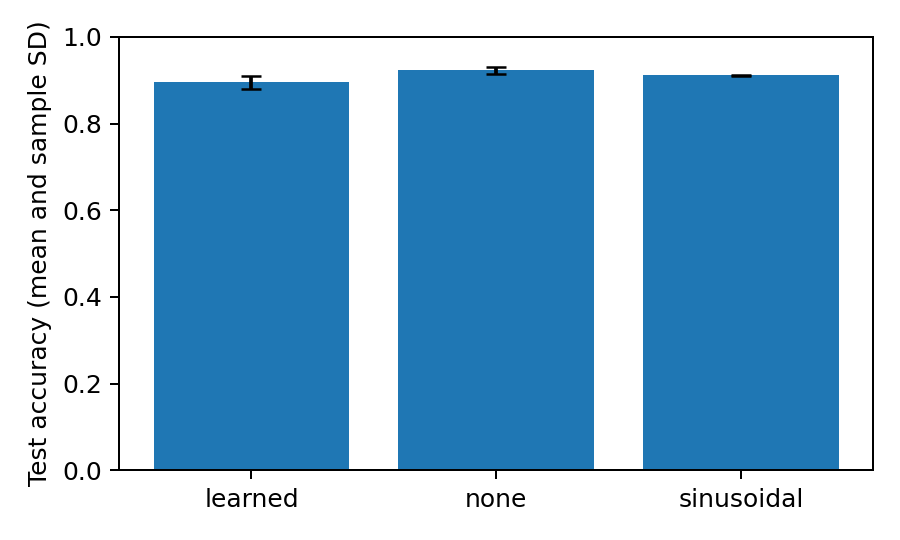

Figure 9. Language-model curves.


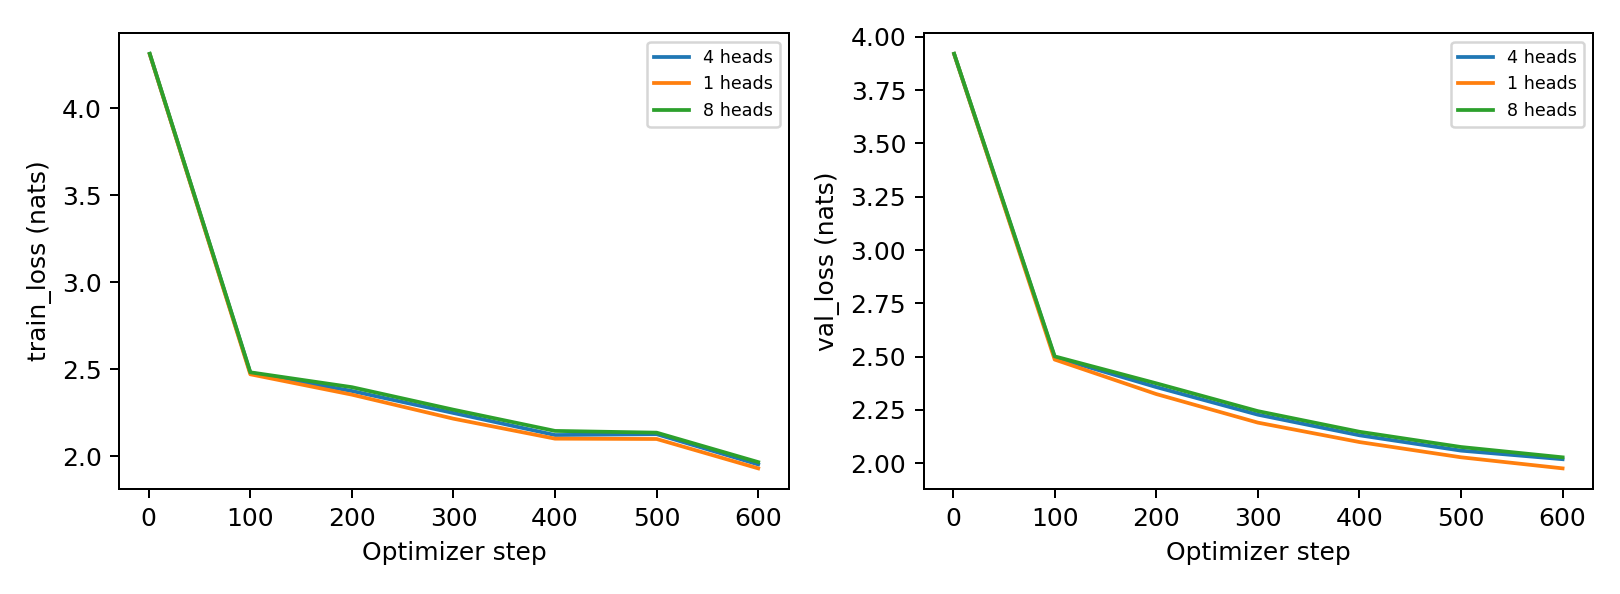

Figure 10. Two attention heads.


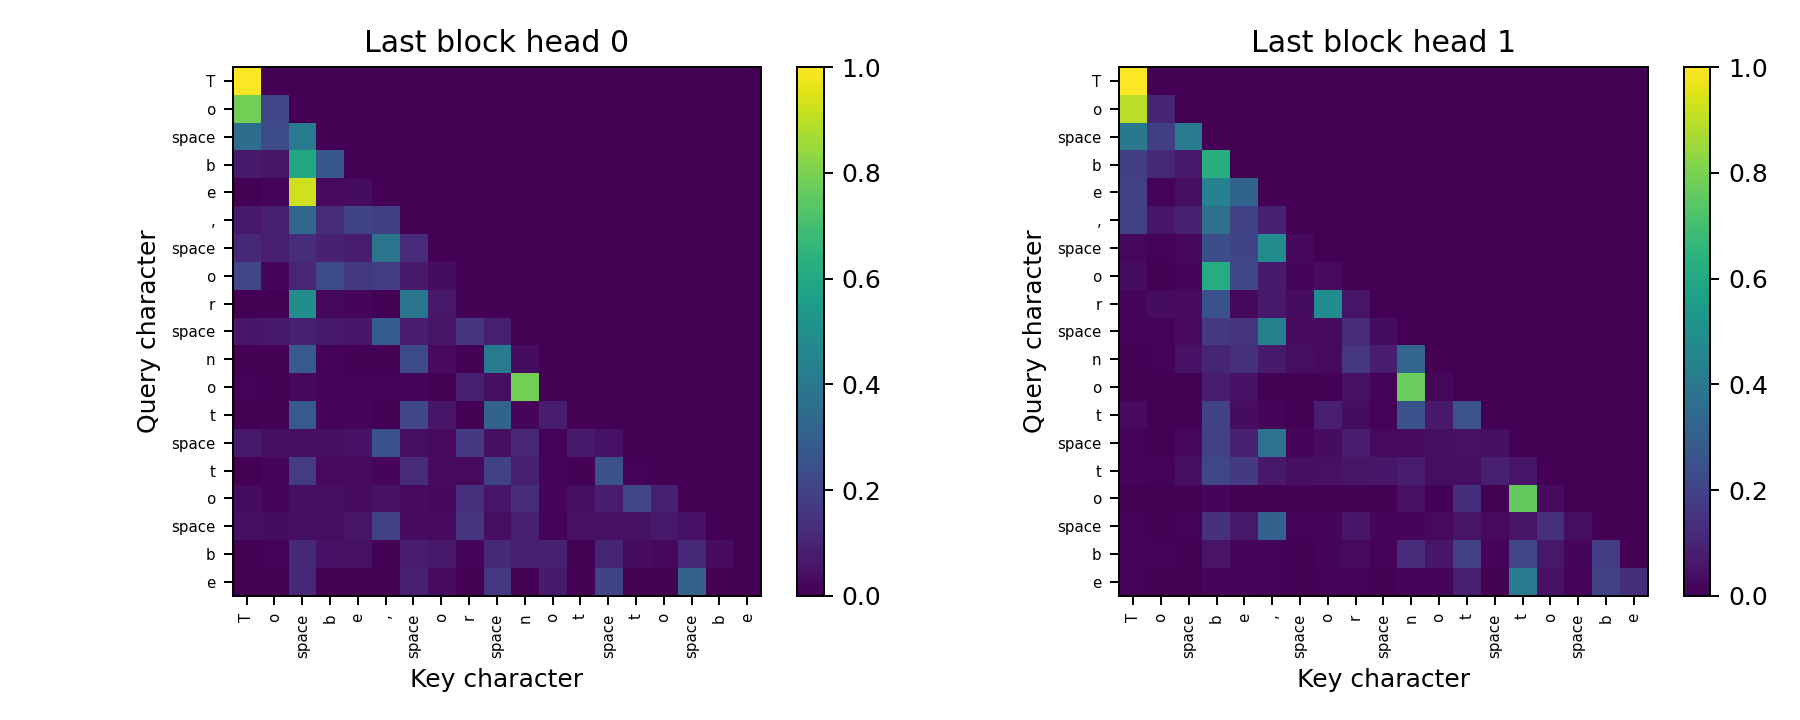

Figure 11. Head-count ablation.


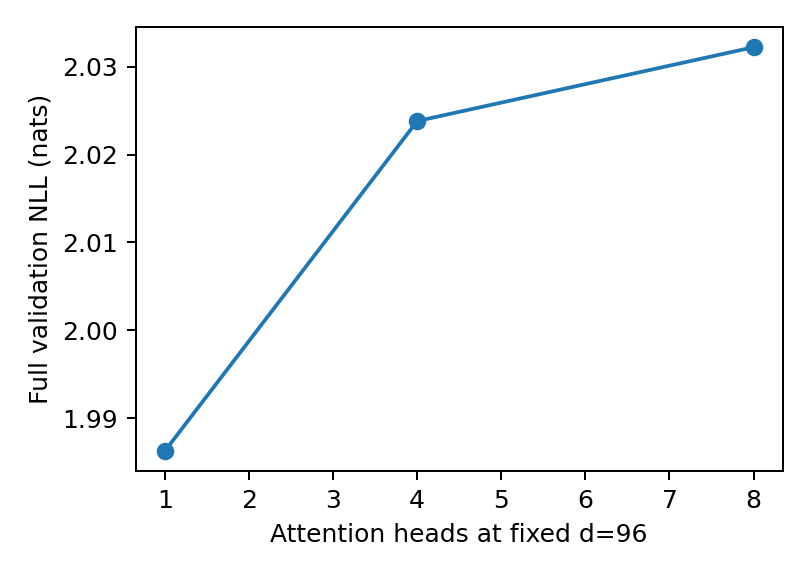

Figure 12. No-mask ablation.


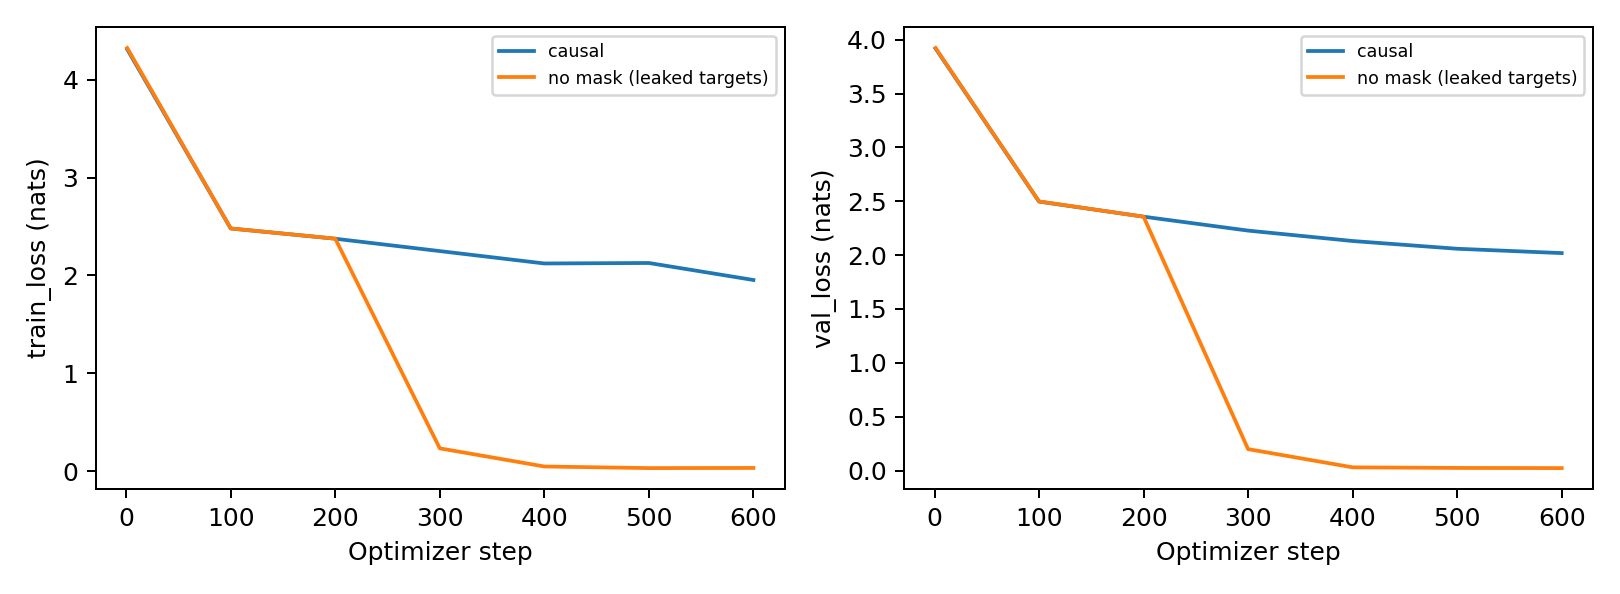

Figure 13. Context timing and memory.


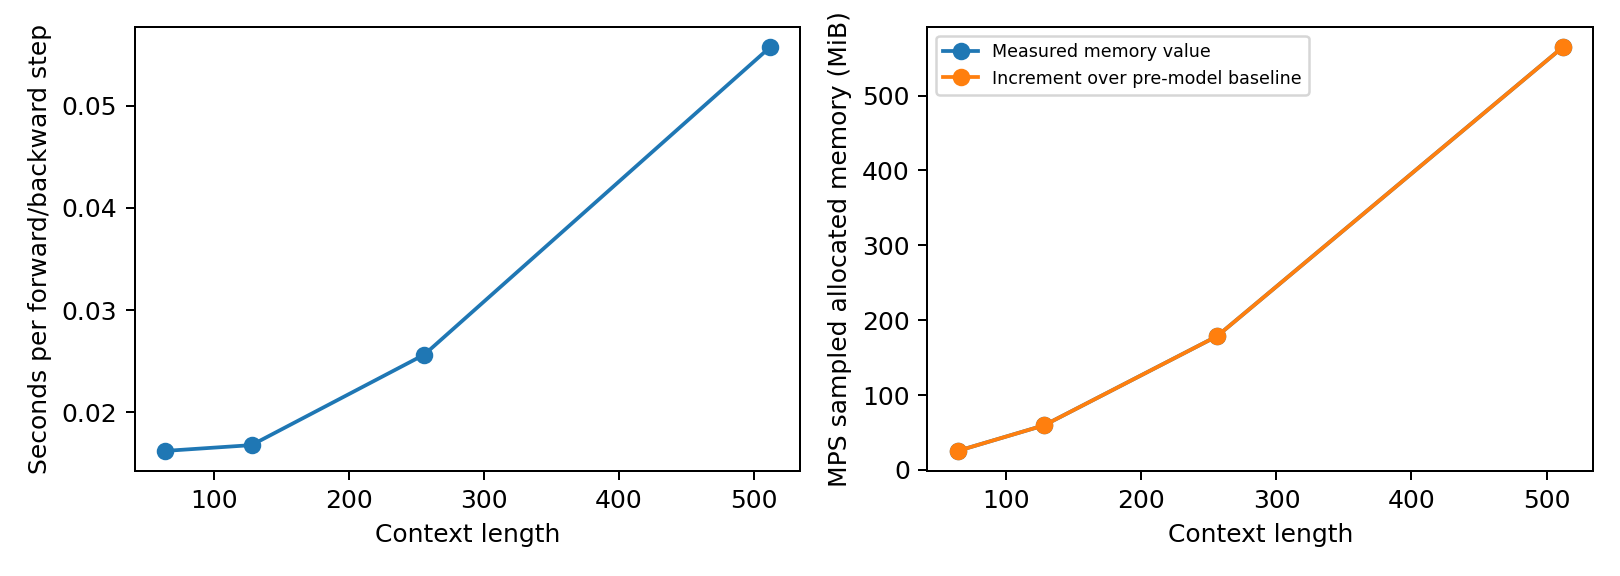

Notebook elapsed: 0.62 minutes. Runtime record: problem2/figures/notebook_runtime.json
This invocation allowed cached results; it is not a full-training benchmark.


In [39]:
figures = ROOT/'problem2/figures'
for filename, caption in [('har_positions.png', 'Figure 8. Positional encoding comparison.'), ('lm_learning_curves.png', 'Figure 9. Language-model curves.'), ('two_attention_heads.png', 'Figure 10. Two attention heads.'), ('heads_ablation.png', 'Figure 11. Head-count ablation.'), ('no_mask_curves.png', 'Figure 12. No-mask ablation.'), ('context_time_memory.png', 'Figure 13. Context timing and memory.')]:
    print(caption)
    display(Image(filename=str(figures/filename)))
finish_notebook_run()
